# BÀI TẬP NÂNG CAO với mô hình SARIMA – Dataset 2 (AirPassengers)

## Bước 6. Forecast & đánh giá (MAE, RMSE)

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
S = 12           # chu kỳ mùa vụ
TEST_SIZE = 24   # 2 năm cuối làm tập kiểm tra

df = pd.read_csv(URL)
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
y = df.set_index("Month")["Passengers"].asfreq("MS")
train, test = y.iloc[:-TEST_SIZE], y.iloc[-TEST_SIZE:]
print(y.shape)
y.head()

(144,)


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

In [2]:
sarima = SARIMAX(train,
                 order=(0, 1, 1),
                 seasonal_order=(0, 1, 1, S),
                 enforce_stationarity=False,
                 enforce_invertibility=False).fit(disp=False)

In [3]:
def evaluate(true, pred, name):
    mae = mean_absolute_error(true, pred)
    rmse = np.sqrt(mean_squared_error(true, pred))
    print(f"{name:>8}: MAE = {mae:8.3f} | RMSE = {rmse:8.3f}")
    return mae, rmse

In [4]:
fc = sarima.get_forecast(steps=TEST_SIZE)
pred_sarima = fc.predicted_mean
ci = fc.conf_int()

res_sarima = evaluate(test, pred_sarima, "SARIMA")

  SARIMA: MAE =   66.275 | RMSE =   71.829


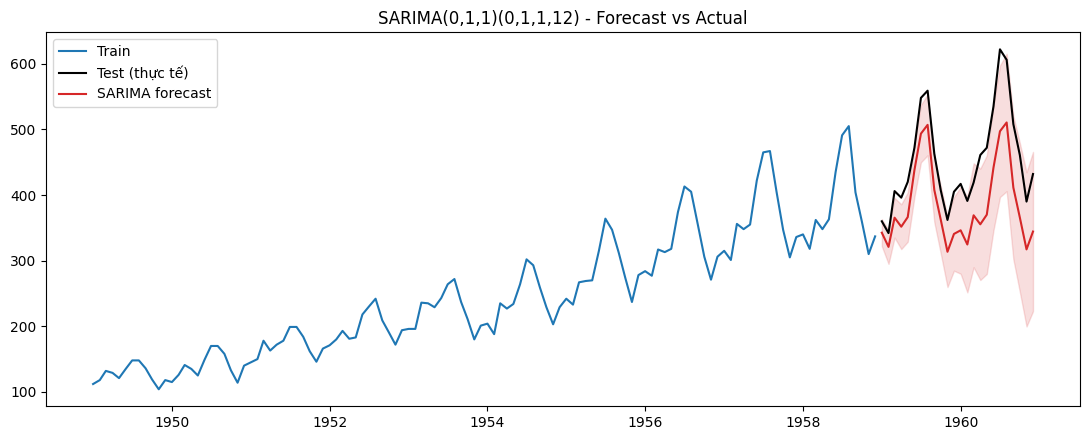

In [5]:
plt.figure(figsize=(11, 4.5))
plt.plot(train, label="Train")
plt.plot(test, label="Test (thực tế)", color="black")
plt.plot(pred_sarima, label="SARIMA forecast", color="tab:red")
plt.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], color="tab:red", alpha=.15)
plt.legend(); plt.title("SARIMA(0,1,1)(0,1,1,12) - Forecast vs Actual")
plt.tight_layout(); plt.show()